In [28]:
import numpy as np
import matplotlib.pyplot as plt
import dask.dataframe as dd
# import trenchripper as tr
import pandas as pd
import h5py
import matplotlib.patches as patches
# %matplotlib inline

In [8]:
import shutil

def writedir(directory,overwrite=False):
    if overwrite:
        if os.path.exists(directory):
            shutil.rmtree(directory)
        os.makedirs(directory)
    else:
        if not os.path.exists(directory):
            os.makedirs(directory)

import os
import shutil
import dask
import time
import h5py
import threading
import dask.distributed

from time import sleep
from dask.distributed import Client,progress
from dask.distributed.diagnostics.plugin import WorkerPlugin
from dask_jobqueue import SLURMCluster

# from IPython.core.display import display, HTML
from IPython.display import display, HTML

## Hacky memory trim
import ctypes
import gc

def trim_memory() -> int:
    libc = ctypes.CDLL("libc.so.6")
    return libc.malloc_trim(0)

class dask_controller: #adapted from Charles' code
    def __init__(self,n_workers=6,n_workers_min=6,local=True,queue="short",death_timeout=60.,\
                 walltime='01:00:00',cores=1,processes=1,memory='6GB',\
                 working_directory="./",job_extra_directives=[]):
        self.local = local
        self.n_workers = n_workers
        self.n_workers_min = n_workers_min
        self.walltime = walltime
        self.queue = queue
        self.death_timeout = death_timeout
        self.processes = processes
        self.memory = memory
        self.cores = cores
        self.working_directory = working_directory
        self.job_extra_directives = job_extra_directives

        self.futures = {}

        split_walltime = walltime.split(":")
        wall_hrs,wall_mins,wall_secs = tuple(split_walltime)
        ttl_wall_mins = (60*int(wall_hrs)) + int(wall_mins)

        if ttl_wall_mins < 10:
            raise ValueError("Walltime must be at least 10 mins long!")

        self.lifetime = str(max(ttl_wall_mins-10,10)) + "m"
        print(self.lifetime)
        print(walltime)
        self.worker_extra_args = ["--lifetime", self.lifetime, "--lifetime-stagger", "5m"]

        writedir(working_directory,overwrite=False)

    def startdask(self):
        if self.local:
            self.daskclient = Client()
            self.daskclient.cluster.scale(self.n_workers)
        else:
            self.daskcluster = SLURMCluster(n_workers=self.n_workers_min,queue=self.queue,death_timeout=self.death_timeout,walltime=self.walltime,\
                                   processes=self.processes,memory=self.memory,cores=self.cores,local_directory=self.working_directory,\
                                log_directory=self.working_directory,worker_extra_args=self.worker_extra_args,job_extra_directives=self.job_extra_directives)
            self.daskcluster.adapt(minimum=self.n_workers_min, maximum=self.n_workers,\
                                   interval="1m",wait_count=10)
            self.daskclient = Client(self.daskcluster)

    def shutdown(self, delete_files=True):
        self.reset_worker_memory()
        if not self.local:
            self.daskcluster.close()
        if delete_files:
            for item in os.listdir(self.working_directory):
                if "worker-" in item or "slurm-" in item or ".lock" in item:
                    path = "./" + item
                    if os.path.isfile(path):
                        os.remove(path)
                    elif os.path.isdir(path):
                        shutil.rmtree(path)

    def printprogress(self):
        complete = len([item for item in self.futures if item.status=="finished"])
        print(str(complete) + "/" + str(len(self.futures)))

    def displaydashboard(self):
        link = self.daskcluster.dashboard_link
        display(HTML('<a href="' + link +'">Dashboard</a>'))

    def mapfovs(self,function,fov_list,retries=0):
        self.function = function
        self.retries = retries
        def mapallfovs(fov_number,function=function):
            function(fov_number)
        self.futures = {}
        for fov in fov_list:
            future = self.daskclient.submit(mapallfovs,fov,retries=retries)
            self.futures[fov] = future

    def retry_failed(self):
        self.failed_fovs = [fov for fov,future in self.futures.items() if future.status != 'finished']
        out = self.daskclient.restart()
        self.mapfovs(self.function,self.failed_fovs,retries=self.retries)

    def retry_processing(self):
        self.proc_fovs = [fov for fov,future in self.futures.items() if future.status == 'pending']
        out = self.daskclient.restart()
        self.mapfovs(self.function,self.proc_fovs,retries=self.retries)

    def restart(self):
        self.daskclient.restart()
        with self.failure_lock:
            self.failure_counter_variable.set(0)

    def reset_worker_memory(self):
        self.daskclient.cancel([val for key,val in self.futures.items()])
        self.daskclient.run(gc.collect)
        self.daskclient.run(trim_memory)
        print("Done.")

class hdf5lock:
    def __init__(self,filepath,updateperiod=0.1):
        self.filepath = filepath
        self.lockfile = filepath + ".lock"
        self.updateperiod = updateperiod

    def _lock(self):
        while True:
            if not os.path.exists(self.lockfile):
                open(self.lockfile,'w').close()
                break
            sleep(self.updateperiod)

    def _apply_fn(self,function,iomode,*args,**kwargs):
        try:
            fn_output = function(self.filepath,iomode,*args,**kwargs)
            os.remove(self.lockfile)
            return fn_output
        except:
            os.remove(self.lockfile)
            raise

    def lockedfn(self,function,iomode,*args,**kwargs):
        self._lock()
        fn_output = self._apply_fn(function,iomode,*args,**kwargs)
        return fn_output

def transferjob(sourcedir,targetdir,single_file=False):
    mkdircmd = "mkdir -p '" + targetdir + "'"
    if single_file:
        rsynccmd = "rsync -r '" + sourcedir + "' '" + targetdir + "'"
    else:
        rsynccmd = "rsync -r '" + sourcedir + "/' '" + targetdir + "'"
    wrapcmd = mkdircmd + " && " + rsynccmd
    cmd = "sbatch -p transfer -t 0-12:00 --wrap=\"" + wrapcmd + "\""
    print(cmd)
    os.system(cmd)


In [10]:
import plotly.graph_objects as go
img_rgb = [[[255, 0, 0], [0, 255, 0], [0, 0, 255]],
           [[0, 255, 0], [0, 0, 255], [255, 0, 0]]]
fig = go.Figure(go.Image(z=img_rgb))

# fig.show(renderer='iframe')
# fig.show(renderer='iframe_connected')
fig.show(renderer='colab')

In [12]:
# addition of active memory manager
import dask
dask.config.set({'distributed.scheduler.active-memory-manager.start': True});
dask.config.set({'distributed.scheduler.worker-ttl': "5m"});
dask.config.set({'distributed.scheduler.allowed-failures': 100});

dask_wd = "/home/lag36/scratch/lag36/dask"

In [14]:
# dask_controller = tr.trcluster.dask_controller(
dask_controller = dask_controller(
    walltime="3:00:00",
    local=False,
    n_workers=20,
    n_workers_min=20,#200,
    memory="8GB",
    working_directory=dask_wd,
)
dask_controller.startdask()

# dask_controller = tr.trcluster.dask_controller(
#     walltime="2:00:00",
#     local=False,
#     n_workers=50,
#     n_workers_min=50,
#     memory="8GB",
#     working_directory=dask_wd,
# )
# dask_controller.startdask()

170m
3:00:00


2025-01-28 13:48:22,588 - distributed.scheduler - ERROR - Couldn't gather keys: {('repartitiontofewer-350fb452d70c46d3a04e0c26b2f7b4db', 0): 'memory'}
2025-01-28 13:48:48,160 - distributed.scheduler - ERROR - Couldn't gather keys: {('repartitiontofewer-350fb452d70c46d3a04e0c26b2f7b4db', 0): 'memory'}
Task exception was never retrieved
future: <Task finished name='Task-153649' coro=<Client._gather.<locals>.wait() done, defined at /home/lag36/miniconda3/envs/minitrenchripper/lib/python3.13/site-packages/distributed/client.py:2394> exception=AllExit()>
Traceback (most recent call last):
  File "/home/lag36/miniconda3/envs/minitrenchripper/lib/python3.13/site-packages/distributed/client.py", line 2403, in wait
    raise AllExit()
distributed.client.AllExit


In [15]:
dask_controller.daskclient

Connection method: Cluster object,Cluster type: dask_jobqueue.SLURMCluster
Dashboard: http://10.120.16.171:8787/status,
Dashboard: http://10.120.16.171:8787/status,Workers: 0
Total threads: 0,Total memory: 0 B
Comm: tcp://10.120.16.171:34239,Workers: 0
Dashboard: http://10.120.16.171:8787/status,Total threads: 0
Started: Just now,Total memory: 0 B


In [17]:
import pandas as pd
headpath = "/home/lag36/scratch/lag36/2024-12-12_lLAG8_EZRDM_Run-02_3-Fiducials_Auto-Media-Switch/Barcodes"
df_2_1 = pd.read_hdf(headpath+'/barcode_output_df_fiducials_hamming-0_rm-1-28.hdf5')
# df_2_1

In [18]:
# Translates from dd to df
bc_kymo_metadata = dd.read_parquet(headpath+"/kymograph/metadata", calculate_divisions=True)
bc_kymo_metadata_df = bc_kymo_metadata.compute()
# Change the type of the lane orientation column to category
bc_kymo_metadata_df["lane orientation"] = bc_kymo_metadata_df["lane orientation"].astype(object)
bc_kymo_metadata_df.to_hdf(headpath+"/kymograph_metadata_df.hdf5", key='data')

KeyboardInterrupt: 

In [19]:
bc_kymo_metadata_df = pd.read_hdf(headpath+"/kymograph_metadata_df.hdf5", key='data')

In [20]:
hdf5_metadata_df = pd.read_hdf("/home/lag36/scratch/lag36/2024-12-12_lLAG8_EZRDM_Run-02_3-Fiducials_Auto-Media-Switch/Barcodes/metadata.hdf5")

In [21]:
dask_controller.shutdown()

Done.


In [22]:
df_lookup = (df_2_1
             .loc[:,['trenchid', 'Barcode Signal', 'Barcode', 'closest_match',  'barcode depth', 'Closest Hamming Distance', 'Category', 'barcode', 'barcodeid']]
             .merge(bc_kymo_metadata_df.groupby('trenchid').first().reset_index(),
                    left_on='trenchid',
                    right_on='trenchid', how='left')
                )

In [23]:
hdf5_metadata_df

channel_paths config  \
fov timepoints                                                             
0   0           {'BF': '/home/lag36/scratch/lag36/2024-12-12_l...     BF   
    1           {'BF': '/home/lag36/scratch/lag36/2024-12-12_l...     BF   
    2           {'BF': '/home/lag36/scratch/lag36/2024-12-12_l...     BF   
    3           {'BF': '/home/lag36/scratch/lag36/2024-12-12_l...     BF   
    4           {'BF': '/home/lag36/scratch/lag36/2024-12-12_l...     BF   
...                                                           ...    ...   
755 10          {'BF': '/home/lag36/scratch/lag36/2024-12-12_l...     BF   
    11          {'BF': '/home/lag36/scratch/lag36/2024-12-12_l...     BF   
    12          {'BF': '/home/lag36/scratch/lag36/2024-12-12_l...     BF   
    13          {'BF': '/home/lag36/scratch/lag36/2024-12-12_l...     BF   
    14          {'BF': '/home/lag36/scratch/lag36/2024-12-12_l...     BF   

                       t       x        y        z  File Index  Image Index  
fov timepoints                                                               
0   0              0.666  5470.0  14446.9  2976.60           0            0  
    1              0.456  5470.1  14446.9  2973.18           0            1  
    2              0.681  5470.0  14447.0  2972.58           0            2  
    3              0.619  5470.0  14446.9  2972.20           0            3  
    4              0.618  5470.0  14446.9  2972.00           0            4  
...                  ...     ...      ...      ...         ...          ...  
755 10          4342.032  5470.0  25293.0  2980.40         755           10  
    11          4340.741  5470.1  25292.9  2979.84         755           11  
    12          4336.821  5470.1  25293.0  2979.52         755           12  
    13          4338.600  5470.0  25293.0  2979.30         755           13  
    14          4342.378  5470.1  25293.0  2979.36         755           14  

[11340 rows x 8 columns]

In [24]:
df_lookup.columns

Index(['trenchid', 'Barcode Signal', 'Barcode', 'closest_match',
       'barcode depth', 'Closest Hamming Distance', 'Category', 'barcode',
       'barcodeid', 'fov', 'row', 'trench', 'timepoints', 'time (s)',
       'lane orientation', 'y (local)', 'x (local)', 'y (global)',
       'x (global)', 'Global Row', 'File Index', 'File Trench Index',
       'File Parquet Index', 'Trenchid Timepoint Index'],
      dtype='object')

In [ ]:
# For a given trench id, I need the y (local), x (local) coordinates,
# The File Index, and File Trench Index
# Also, I need the fov to get it from the hdf df


In [30]:
import plotly.graph_objects as go
img_rgb = [[[255, 0, 0], [0, 255, 0], [0, 0, 255]],
           [[0, 255, 0], [0, 0, 255], [255, 0, 0]]]
fig = go.Figure(go.Image(z=img_rgb))

# fig.show(renderer='iframe')
# fig.show(renderer='iframe_connected')
fig.show(renderer='colab')

In [1]:
# Plotly version




microns_per_pixel = 0.105951961895293*2
max_x, max_y = 2960, 2960
trenchid = 3242
df_lookup.loc[df_lookup["trenchid"] == trenchid, :]
fov, x, y = df_lookup.loc[df_lookup["trenchid"] == trenchid, ["fov", "x (local)", "y (local)"]].values[0]
fov, x ,y
x /= microns_per_pixel
y /= microns_per_pixel

t = 14
file_index, image_index = hdf5_metadata_df.loc[(fov, t), ["File Index", "Image Index"]]

with h5py.File(headpath+"/hdf5/hdf5_"+str(file_index)+".hdf5", "r") as f:
    print(f['RFP'][image_index].shape)
    # plt.imshow(f['RFP'][image_index])
    img = f['RFP'][image_index]
    # fig = go.Figure(data = go.Image(z=f['RFP'][image_index]))
    # fig.show(renderer='colab')

NameError: name 'df_lookup' is not defined

In [2]:
x, y

NameError: name 'x' is not defined

In [ ]:
fig.update_layout(
    xaxis=dict(range=[0, img.shape[1]], autorange=False),
    yaxis=dict(range=[img.shape[0], 0], autorange=False)  # Invert y-axis for image coordinates
)

In [55]:
x, y

(np.float64(2478.5), np.float64(2089.0))

In [59]:
import plotly.express as px
fig_single = px.imshow(img, color_continuous_scale='gray', width = 1000, height = 1000, zmin = 1300, zmax = 8000)

# fig.add_trace( go.Scatter(x=[x, 2960],y=[y, 2960], mode='markers', marker=dict(color=['red'])) )
x_points = [x]
y_points = [y]

fig_single.add_shape(type="rect",
              x0=x, y0=y, x1=x+50, y1=y+50,
              line=dict(color="red"),
              fillcolor="rgba(255, 0, 0, 0.2)") # Semi-transparent red

# fig.add_trace(go.Scatter(
#     x=x_points,
#     y=y_points,
#     mode='markers',
#     marker=dict(color='red', size=50),
#     name='Points'
# ))

# fig.update_layout(
#     xaxis=dict(range=[0, img.shape[1]], autorange=False),
#     yaxis=dict(range=[img.shape[0], 0], autorange=False)  # Invert y-axis for image coordinates
# )

fig_single.show(renderer='colab')

200 200 200 200


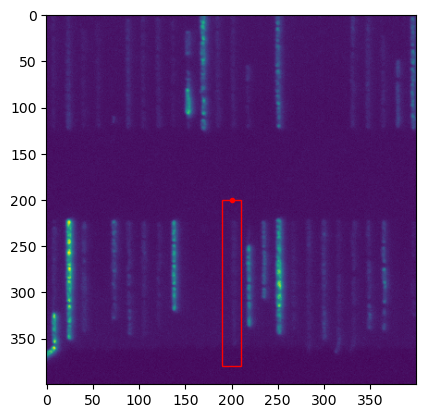

In [29]:
microns_per_pixel = 0.105951961895293*2
max_x, max_y = 2960, 2960
trenchid = 3242
df_lookup.loc[df_lookup["trenchid"] == trenchid, :]
fov, x, y = df_lookup.loc[df_lookup["trenchid"] == trenchid, ["fov", "x (local)", "y (local)"]].values[0]
fov, x ,y
x /= microns_per_pixel
y /= microns_per_pixel

t = 14
file_index, image_index = hdf5_metadata_df.loc[(fov, t), ["File Index", "Image Index"]]

delta_x, delta_y = 200, 200
delta_x_left = min(int(x), delta_x)
delta_x_right = min(max_x - int(x), delta_x)
delta_y_up = min(int(y), delta_y)
delta_y_down = min(max_y - int(y), delta_y)

x_prime = delta_x_left
y_prime = delta_y_up

print(delta_x_left, delta_x_right, delta_y_up, delta_y_down)
with h5py.File(headpath+"/hdf5/hdf5_"+str(file_index)+".hdf5", "r") as f:
    fig, ax = plt.subplots()

    
    ax.imshow(f['RFP'][image_index][int(y)-delta_y_up:int(y)+delta_y_down, int(x)-delta_x_left:int(x)+delta_x_right])
    ax.plot(x_prime, y_prime, 'r.')

    # Draw a rectangle around the trench
    rect = patches.Rectangle((int(x_prime)-10, int(y_prime)), 20, 180, linewidth=1, edgecolor='r', facecolor='none')
    ax.add_patch(rect)
    # plt.plot([int(x_prime)-10, int(x_prime)+10], [int(y_prime)-10, int(y_prime)+10], 'r-')
    # plt.show()
    

In [104]:
# # Open the hdf5 image file
# channel = 'BF'
# with h5py.File(headpath+"/hdf5/hdf5_"+str(file_index)+".hdf5", "r") as f:
#     plt.figure(figsize=(20, 20))
#     max_x, max_y = f['BF'][image_index].shape
#     plt.imshow(f['BF'][image_index])
#     print(f['BF'][image_index].shape)
#     plt.plot(x, y, 'ro')
#     plt.show()

200 200 200 200


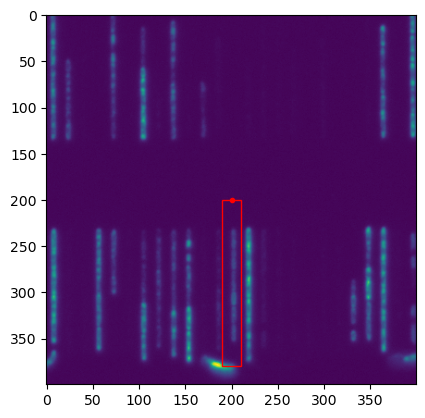

In [106]:
### QC segmentation
import h5py
import matplotlib.pyplot as plt
import numpy as np

def show_kymograph(
        path_prefix,
        path_kymo_dir_prefix,
        channels,
        cmap,
        kymo_file_index,
        trench_index,
        t_indices,
        figsize,
        Barcode = None,
        barcode_phe = None #translated from seq barcode
        ):
    
    n_cycles_per_ch = 15 # TODO GENERALIZE
    with h5py.File(path_prefix + path_kymo_dir_prefix + str(kymo_file_index) + ".hdf5", "r") as infile:
        for i_ch, ch in enumerate(channels):
            img = infile[ch][trench_index][t_indices[0]]
            for ind in t_indices[1:]:
                img_ind = infile[ch][trench_index][ind]
                img = np.concatenate((img, img_ind), axis=1)
            plt.figure(figsize=figsize)
            # Do not show axes ticks
            plt.xticks([])
            plt.yticks([])
            plt.imshow(img, cmap=cmap, aspect=1)
            # Annotate the kymo_file_index and the trench index at the bottom left corner
            plt.annotate(f'kymo_file_index: {kymo_file_index}, trench index: {trench_index}', (10, 15), color='white')
            # Annotate the cycle number at the bottom of each slice
            for i, ind in enumerate(t_indices):
                # plt.annotate(f'{ind}', (i*9+9/4, 160), color='white', fontsize=8) # 13 is the width of a slice
                plt.annotate(f'{ind}', (i*11+11/4, 160), color='white', fontsize=8) # 13 is the width of a slice
            # Annotate the Barcode bit at the bottom of each slice
            if Barcode is not None:
                
                for i, bit in enumerate(Barcode[i_ch*n_cycles_per_ch:(i_ch+1)*n_cycles_per_ch]):
                    # plt.annotate(f'{bit}', (i*9+9/3, 140), color='yellow', fontsize=8) # 13 is the width of a slice
                    plt.annotate(f'{bit}', (i*11+11/3, 140), color='yellow', fontsize=8) # 13 is the width of a slice
            # Annotate the barcode bit at the bottom of each slice
            if barcode_phe is not None:
                for i, bit in enumerate(barcode_phe[i_ch*n_cycles_per_ch:(i_ch+1)*n_cycles_per_ch]):
                    # plt.annotate(f'{bit}', (i*9+9/3, 120), color='red', fontsize=8) # 13 is the width of a slice
                    plt.annotate(f'{bit}', (i*11+11/3, 120), color='red', fontsize=8) # 13 is the width of a slice
            plt.show()
            plt.close()

def map_bc_to_pheno(barcode,
                    cycleorder = [0,1,6,7,12,13,18,19,24,25,4,5,10,11,16,
                                  2,3,8,9,14,15,20,21,26,27,17,22,23,28,29],
                    ):
    barcode_phe = [-1]*30
    for i, bit in enumerate(barcode):
        # print(i, bit)
        # Find the position of i in cycleorder
        i_phe = cycleorder.index(i)
        barcode_phe[i_phe] = bit
    barcode_phe = ''.join(barcode_phe)
    return barcode_phe

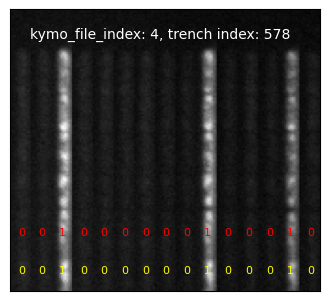

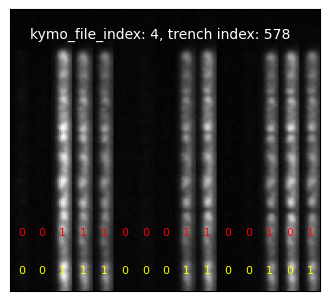

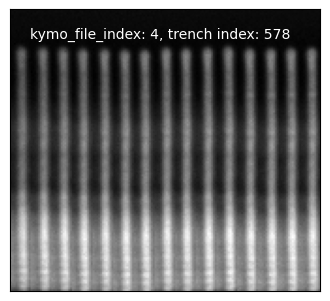

In [131]:
trenchid = 3242
bc_kymo_file_index, bc_trench_index, Barcode, barcode = df_lookup.loc[df_lookup['trenchid'] == trenchid, ['File Index', 'File Trench Index', 'Barcode', 'barcode']].values[0]
bc_kymo_file_index = int(bc_kymo_file_index)
bc_trench_index = int(bc_trench_index)
# barcode (lowercase) comes from sequencing (red)
# Barcode (uppercase) comes from trench signal (yellow)
# Barcode, barcode = df_lookup.loc[row, ['Barcode', 'barcode']]
barcode_phe = map_bc_to_pheno(barcode)
figsize = (4, 8)
path_prefix = headpath+"/"
path_kymo_dir_prefix = "kymograph/kymograph_"
# channels = ["BF", "RFP", "Cy5"]
channels = ["RFP", "Cy5"]
cmap = "gray"
t_indices = np.arange(0,15)
show_kymograph(path_prefix, path_kymo_dir_prefix, channels, cmap, bc_kymo_file_index, bc_trench_index, t_indices, figsize, Barcode, barcode_phe)
show_kymograph(path_prefix, path_kymo_dir_prefix, ['BF'], cmap, bc_kymo_file_index, bc_trench_index, t_indices, figsize, None, None)